In [343]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets

iris = datasets.load_iris()
X = iris.data
y = iris.target

print(X.shape)
print(np.unique(y, return_counts=True))

(150, 4)
(array([0, 1, 2]), array([50, 50, 50]))


Normalizacja danych

In [344]:
X_norm = X.copy()

for i in range(4):
    min_val = X_norm[:,i].min()
    max_val = X_norm[:,i].max()
    X_norm[:,i] = (X_norm[:,i]-min_val)/(max_val-min_val)

print(X_norm[range(10), :], "\n", X_norm.min(), X_norm.max())

[[0.22222222 0.625      0.06779661 0.04166667]
 [0.16666667 0.41666667 0.06779661 0.04166667]
 [0.11111111 0.5        0.05084746 0.04166667]
 [0.08333333 0.45833333 0.08474576 0.04166667]
 [0.19444444 0.66666667 0.06779661 0.04166667]
 [0.30555556 0.79166667 0.11864407 0.125     ]
 [0.08333333 0.58333333 0.06779661 0.08333333]
 [0.19444444 0.58333333 0.08474576 0.04166667]
 [0.02777778 0.375      0.06779661 0.04166667]
 [0.16666667 0.45833333 0.08474576 0.        ]] 
 0.0 1.0


Neurony

In [345]:
neurons = np.random.rand(3, 4)

neurons

array([[0.08729884, 0.93959604, 0.25129635, 0.6258641 ],
       [0.30620125, 0.44204221, 0.60848251, 0.14317444],
       [0.25776613, 0.22504011, 0.90874879, 0.09236042]])

Funkcja odległości

In [346]:
def distanceMySOM(T, N):
    if T.shape != N.shape:
        raise ValueError("Neuron i cel mają inne wymiary!")
    return np.sum((T - N)**2) #liczenie pierwiastka w przypadku porównywania odległości do celu nie ma sensu

Szukanie zwycięzcy (BMU)

In [347]:
def getBMU(T, N):
    distances = []
    for neuron in N:
        distances.append(distanceMySOM(T, neuron))
    return np.argmin(distances)

Aktualizacja wag

In [348]:
def updateWeights(T, N, W, lr):
    N[W] = N[W] + lr * (T - N[W])

Pętla ucząca

In [349]:
epo = 100
lr = 0.1

for i in range(epo):
    index = np.random.permutation(len(X_norm))
    for idx in index:
        updateWeights(X_norm[idx], neurons, getBMU(X_norm[idx], neurons), lr)
    lr = lr * 0.95

neurons

array([[0.19613742, 0.59501527, 0.07830474, 0.06081757],
       [0.70735151, 0.45099399, 0.7970914 , 0.82475766],
       [0.44114928, 0.30728344, 0.57570578, 0.5492005 ]])

In [350]:
check = []
for i in X_norm:
    check.append(getBMU(i, neurons))
p = pd.crosstab(y, check, rownames=['Prawdziwy gatunek'], colnames=['Zwycięski neuron'])
p

Zwycięski neuron,0,1,2
Prawdziwy gatunek,,,
0,50,0,0
1,0,3,47
2,0,36,14


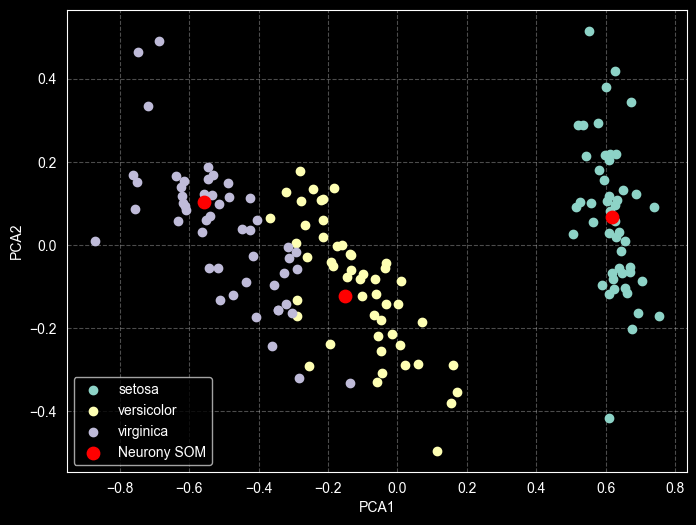

In [351]:
class PCA:

    def __init__(self):
        self.mean = None
        self.cov = None
        self.eigen_values = None
        self.eigen_vectors = None
        self.pro_eigen_values = None
        self.sum_pro_eigen_values = None

    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        x_centered = X - self.mean
        n = x_centered.shape[0]
        self.cov = (x_centered.T @ x_centered) / (n-1)
        self.eigen_values, self.eigen_vectors = np.linalg.eigh(self.cov)
        order = np.argsort(self.eigen_values)[::-1]
        self.eigen_values = self.eigen_values[order]
        self.eigen_vectors = self.eigen_vectors[:, order]
        sum_eigen_values = np.sum(self.eigen_values)
        self.pro_eigen_values = self.eigen_values / sum_eigen_values
        self.sum_pro_eigen_values = np.cumsum(self.pro_eigen_values)
        return f'{45*'-'}\nProcentowy udział cech w zmienności danych:\n{self.pro_eigen_values}\nSkomulowany:\n{self.sum_pro_eigen_values}\n{45*'-'}'

    def transform(self, X, n_components=None):
        return (X - self.mean) @ self.eigen_vectors[:, :n_components]

combined_data = np.vstack([X_norm, neurons])

pca = PCA()
pca.fit(combined_data)

combined_2d = pca.transform(combined_data, 2)

X_pca = combined_2d[:150]
neurons_pca = combined_2d[150:]

plt.figure(figsize=(8, 6))

for class_id, class_name in enumerate(iris.target_names):
    mask = y == class_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=class_name,
    )

plt.scatter(
    neurons_pca[:, 0],
    neurons_pca[:, 1],
    color="red",
    s=80,
    marker="o",
    label="Neurony SOM",
)

plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()